# Timing GPU work in a Phlex job: the minimal CUDA benchmark pattern

`gpu-hello-world.ipynb` showed how to call CUDA code from Phlex. This notebook **times** it. The
work is SAXPY, `z = a·x + y` on vectors of `n` floats: the "hello world" of GPU performance.

When you finish, you will be able to:
- write a GPU benchmark that gives numbers you can trust (the minimal benchmark pattern)
- tell kernel time, transfer time and CPU time apart, and compute an effective bandwidth
- use a Phlex layer to scan a parameter: here, one problem size per spill
- read the result: when a GPU helps, and when copying the data costs more than the GPU saves

Do `gpu-hello-world.ipynb` first. This notebook uses the same layout and the same setup.

## The minimal CUDA benchmark pattern

Timing a GPU is easy to get wrong. The pattern is a checklist:

| # | Rule | Why |
|---|---|---|
| 1 | **Warm up** with one untimed launch | The first launch pays one-off costs (loading the kernel onto the device, and more) |
| 2 | **Time with CUDA events**, not a CPU clock | Launches are asynchronous: a CPU clock measures how long it took to *queue* the work |
| 3 | **Average many launches** | One launch of a small kernel takes a few microseconds, close to the timer's resolution |
| 4 | **Check errors** after the launches | A kernel that failed to launch takes no time at all, and looks very fast |
| 5 | **Verify** the answer against the CPU | A fast wrong answer is worthless |
| 6 | **Time the copies separately** | Host↔device copies over PCIe are often slower than the kernel itself |
| 7 | **Report a meaningful rate** | GB/s for memory-bound kernels like SAXPY; FLOP/s for compute-bound ones |

and one rule from Phlex: **8. give the benchmark the GPU to itself.** Register the GPU algorithm with
`concurrency::serial`, so no other spill's work is on the GPU while you time.

> 🧭 **Analogy:** timing a GPU kernel with the CPU clock is like timing a courier from the moment you
> drop the parcel at the counter. The counter takes it in a second; the delivery takes a day. CUDA
> events are a tracking number that is scanned at the door.

## The plan

```
 spill ──► problem_size_source ──► log2_n ──► transform "saxpy_gpu" ──► timing ──► observer "record"
  (14 spills: n = 2^12 ... 2^25)                (serial, one size     (struct)     (serial: prints a line,
                                                 at a time on GPU)                   appends to a CSV)
```

Each **spill is one problem size**. The layer machinery that usually splits a run into events here
splits a scan into points: you get a parameter scan without writing a loop.

# Section 0: Software setup

You need **phlex**, **CMake 3.31 or later**, a C++ compiler, the **CUDA toolkit** (`nvcc`) and a
**GPU** that the kernel can see.

**Check the kernel name at the top right: it should say "PHA India (Apptainer)".** If it says
**Python 3**, switch with **Kernel → Change Kernel…**. The Python 3 kernel runs outside the
container, where there is no phlex or cmake. The PHA India kernel runs inside the image, so every
`!` and `%%bash` cell below can see phlex, and it starts the container with `--nv`, so it can see the GPU.

Run the next cell to check that the tools and the GPU are visible. Run it again if you restart the kernel.

In [57]:
!which phlex cmake c++ nvcc nvidia-smi
!cmake --version | head -1
!nvcc --version | tail -2
!phlex --version
!nvidia-smi -L || echo "nvidia-smi found no GPU"

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
/cvmfs/phaindia.example.org/env/phaindia/view/bin/phlex
/cvmfs/phaindia.example.org/env/phaindia/view/bin/cmake
/cvmfs/phaindia.example.org/opt/__spack_path_placeholder__/__spack_path_placeholder__/__spack_path_placeholder__/__spack_path_pl/gcc-15.3.0-embajaykamenahi5jlsnehycjv27s4fr/bin/c++
/usr/local/cuda-13.2/bin/nvcc
/usr/bin/nvidia-smi
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
Current working directory cannot be established.
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
Cuda compilation tools, release 13.2, V13.2.78
Build cuda_13.2.r13.2/compiler.37668154_0
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
phlex 0.4.1
shell-init: error retrieving current direct

What you should see:

- a path for every tool, and a `release` line from `nvcc`
- at least one line like `GPU 0: NVIDIA A100 ...` from `nvidia-smi -L`

If something is missing, you can still read the code below, but not run it on a GPU. There are two
separate things to check:

- **`nvidia-smi` missing or no GPU listed: the kernel was started without `--nv`.** The GPU driver and
  `nvidia-smi` come from the host, and apptainer only passes them into the container when it is
  started with `--nv`. You cannot add that flag from inside a notebook, because the kernel *is* the
  container: it has to be in the kernel's start command. Use the **PHA India (Apptainer) (GPU)** kernel if
  the kernel menu has one. If not, make your own copy of the kernel with `--nv`, once, in a terminal
  outside the container, from the folder this notebook is in:

  💻 **Terminal, outside the container** (prompt `jupyter-you@dune-tech`)
  ```bash
  python3 make_gpu_kernel.py
  ```

  Then reload this page, choose **PHA India (Apptainer) (GPU)** (top right) and run the cell above again.
  To check by hand first: `apptainer shell --nv --cleanenv <image>.sif`, then `nvidia-smi -L`.
- **`nvcc` missing: the image has no CUDA toolkit.** `--nv` does not help here: it brings the driver,
  not the compiler. The image needs CUDA added (see **Troubleshooting** at the end).

## Paths

You work in `~/phlex-work`, the same folder as the other Phlex tutorials, in a new
`phlex-gpu-examples` directory. The build directory sits next to the source directory, as in the
phlex-examples README:

```
~/phlex-work/phlex-gpu-examples/
├── benchmark/          <- source: the CUDA library, the Phlex plugins, CMakeLists.txt, the configuration
└── build-benchmark/    <- CMake build directory
```

Each `!` cell runs in a new shell, so `cd` or `export` in one cell does not carry over to the next.
The next cell sets the paths as environment variables of the kernel, which every later cell inherits.
It also chooses which GPU architecture to compile for. Run it again if you restart the kernel.

In [58]:
import os
import shutil
import subprocess
from pathlib import Path

WORK = Path.home() / "phlex-work" / "phlex-gpu-examples"
BENCH_SRC = WORK / "benchmark"
BENCH_BUILD = WORK / "build-benchmark"
BENCH_SRC.mkdir(parents=True, exist_ok=True)
BENCH_BUILD.mkdir(parents=True, exist_ok=True)

os.environ["BENCH_SRC"] = str(BENCH_SRC)
os.environ["BENCH_BUILD"] = str(BENCH_BUILD)

# phlex finds plugins (MODULE libraries) through PHLEX_PLUGIN_PATH. Put the build directory first
# and keep what the kernel already has (that is where phlex's own plugins, like generate_layers, are).
entries = os.environ.get("PHLEX_PLUGIN_PATH", "").split(":")
if str(BENCH_BUILD) not in entries:
    os.environ["PHLEX_PLUGIN_PATH"] = ":".join([str(BENCH_BUILD)] + [e for e in entries if e])

# Compile the plugins with the g++ on PATH: the compiler Phlex was built with, and the one nvcc uses
# as its host compiler. Without this, CMake follows a CXX variable from the image, which can name
# a different compiler (such as clang++).
gxx = shutil.which("g++")
if gxx:
    os.environ["CXX"] = gxx

# Find nvcc: on PATH already, or in a CUDA toolkit mounted into the container at /usr/local/cuda*
if not shutil.which("nvcc"):
    for candidate in sorted(Path("/usr/local").glob("cuda*/bin/nvcc"), reverse=True):
        os.environ["PATH"] = f"{candidate.parent}:{os.environ['PATH']}"
        break
nvcc = shutil.which("nvcc")

# CUDA 12 refuses GCC 15 as nvcc's host compiler. If this CUDA is older than 13 and the image's
# compiler is GCC 15 or newer, let nvcc use the operating system's g++ for the .cu files instead.
# The Phlex plugins are still compiled by the image's GCC 15.
os.environ.setdefault("CUDA_CMAKE_ARGS", "")
if nvcc and not os.environ["CUDA_CMAKE_ARGS"]:
    release = subprocess.run([nvcc, "--version"], capture_output=True, text=True).stdout
    cuda_major = int(release.split("release ")[1].split(".")[0]) if "release " in release else 0
    gcc_major = int(subprocess.run(["c++", "-dumpversion"], capture_output=True, text=True).stdout.split(".")[0] or 0)
    system_gxx = Path("/usr/bin/g++")
    if cuda_major and cuda_major < 13 and gcc_major >= 15 and system_gxx.exists():
        os.environ["CUDA_CMAKE_ARGS"] = f"-DCMAKE_CUDA_HOST_COMPILER={system_gxx}"

# Which GPU architecture should nvcc compile for?
#   - a GPU is visible: 'native', the exact GPU(s) in this machine
#   - no GPU visible:   a list of common ones, so that the code at least compiles
gpus = ""
if shutil.which("nvidia-smi"):
    gpus = subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout.strip()
os.environ["CUDA_ARCH"] = "native" if gpus.startswith("GPU") else "75;80;86;89;90"

# To pass other CMake arguments for CUDA, set CUDA_CMAKE_ARGS before running this cell, for example
#   os.environ["CUDA_CMAKE_ARGS"] = "-DCMAKE_CUDA_FLAGS=-allow-unsupported-compiler"

for var in ["BENCH_SRC", "BENCH_BUILD", "PHLEX_PLUGIN_PATH", "CXX", "CUDA_ARCH", "CUDA_CMAKE_ARGS"]:
    print(f"{var:18} {os.environ.get(var, '')}")
print(f"{'nvcc':18} {nvcc or '⚠️  not found: the image has no CUDA toolkit, so the GPU code cannot be built'}")
print()
print(gpus or "⚠️  No GPU visible: you can build, but running the GPU code will fail.")
if not shutil.which("phlex"):
    print("⚠️  phlex not found: this notebook is not on the PHA India (Apptainer) kernel. Switch to it (top right) and run this cell again.")

BENCH_SRC          /data/home/jupyter-ahiguera-mx/phlex-work/phlex-gpu-examples/benchmark
BENCH_BUILD        /data/home/jupyter-ahiguera-mx/phlex-work/phlex-gpu-examples/build-benchmark
PHLEX_PLUGIN_PATH  /data/home/jupyter-ahiguera-mx/phlex-work/phlex-gpu-examples/build-benchmark:/cvmfs/phaindia.example.org/env/phaindia/view/lib
CXX                /cvmfs/phaindia.example.org/opt/__spack_path_placeholder__/__spack_path_placeholder__/__spack_path_placeholder__/__spack_path_pl/gcc-15.3.0-embajaykamenahi5jlsnehycjv27s4fr/bin/g++
CUDA_ARCH          native
CUDA_CMAKE_ARGS    
nvcc               /usr/local/cuda-13.2/bin/nvcc

GPU 0: NVIDIA L4 (UUID: GPU-bde1dfc3-10e8-5346-2236-907401a3dd38)
GPU 1: NVIDIA L4 (UUID: GPU-1ad16762-35f7-3a07-8e50-bf43035bfb9e)


# Section 1: The benchmark library

As before: a plain C++ header, and a `.cu` file compiled by nvcc. The header defines
`saxpy_timing`, a struct of plain numbers. A struct like this can be a Phlex data product, just like
`examples::geometry` in phlex-examples.

In [59]:
%%writefile ~/phlex-work/phlex-gpu-examples/benchmark/my_saxpy_bench.hpp
#ifndef MY_SAXPY_BENCH_HPP
#define MY_SAXPY_BENCH_HPP

// Plain C++ interface to the CUDA benchmark in my_saxpy_bench.cu. No CUDA types appear here, so
// the Phlex plugin that includes this header is compiled by the ordinary C++ compiler.

namespace examples::gpu {

  // Everything one benchmark measures. Plain numbers, so it can be a Phlex data product.
  struct saxpy_timing {
    long long n;          // number of elements in each vector
    int iterations;       // timed kernel launches that were averaged
    double h2d_ms;        // copy x and y host -> device
    double kernel_ms;     // one kernel launch (average over the iterations)
    double d2h_ms;        // copy z device -> host
    double cpu_ms;        // the same calculation on one CPU core
    double kernel_gbps;   // effective bandwidth of the kernel: 3 * n * sizeof(float) / kernel_ms
    float max_abs_error;  // largest |z_gpu - z_cpu|
  };

  // Number of CUDA devices this process can see (0 if there is no GPU or no driver).
  int device_count();

  // z = a * x + y on n floats, with the minimal CUDA benchmark pattern:
  // allocate, copy in (timed), warm up (not timed), time `iterations` launches with CUDA
  // events, check for errors, copy out (timed), verify against the CPU, free.
  // Throws std::runtime_error if any CUDA call fails.
  saxpy_timing benchmark_saxpy(long long n, int iterations);

}

#endif // MY_SAXPY_BENCH_HPP

Overwriting /data/home/jupyter-ahiguera-mx/phlex-work/phlex-gpu-examples/benchmark/my_saxpy_bench.hpp


The implementation follows the checklist. The numbered comments match the steps below.

In [60]:
%%writefile ~/phlex-work/phlex-gpu-examples/benchmark/my_saxpy_bench.cu
#include "my_saxpy_bench.hpp"

#include <cuda_runtime.h>

#include <algorithm>
#include <chrono>
#include <cmath>
#include <stdexcept>
#include <string>
#include <vector>

namespace {

  // z[i] = a * x[i] + y[i]. A grid-stride loop, so any grid size covers any n.
  __global__ void saxpy_kernel(long long const n,
                               float const a,
                               float const* __restrict__ x,
                               float const* __restrict__ y,
                               float* __restrict__ z)
  {
    long long const stride = static_cast<long long>(blockDim.x) * gridDim.x;
    for (long long i = static_cast<long long>(blockIdx.x) * blockDim.x + threadIdx.x; i < n;
         i += stride) {
      z[i] = a * x[i] + y[i];
    }
  }

  void check(cudaError_t const err, char const* what)
  {
    if (err != cudaSuccess) {
      throw std::runtime_error(std::string{what} + " failed: " + cudaGetErrorString(err));
    }
  }

  // Milliseconds between two recorded events. Waits for `stop` to complete first.
  float elapsed_ms(cudaEvent_t const start, cudaEvent_t const stop)
  {
    check(cudaEventSynchronize(stop), "cudaEventSynchronize");
    float ms = 0.f;
    check(cudaEventElapsedTime(&ms, start, stop), "cudaEventElapsedTime");
    return ms;
  }

  constexpr float a = 2.0f;
  constexpr int threads_per_block = 256;

}

namespace examples::gpu {

  int device_count()
  {
    int n = 0;
    if (cudaGetDeviceCount(&n) != cudaSuccess) {
      return 0;
    }
    return n;
  }

  saxpy_timing benchmark_saxpy(long long const n, int const iterations)
  {
    if (n < 1 || iterations < 1) {
      throw std::invalid_argument("benchmark_saxpy: n and iterations must be positive");
    }
    auto const n_elements = static_cast<std::size_t>(n);
    std::size_t const bytes = n_elements * sizeof(float);

    // 1. Host data, with values that are easy to check
    std::vector<float> x(n_elements), y(n_elements), z(n_elements), z_cpu(n_elements);
    for (std::size_t i = 0; i < n_elements; ++i) {
      x[i] = static_cast<float>(i % 1000) / 1000.f;
      y[i] = 1.f - x[i];
    }

    // 2. Device buffers and timing events
    float *d_x = nullptr, *d_y = nullptr, *d_z = nullptr;
    check(cudaMalloc(&d_x, bytes), "cudaMalloc x");
    check(cudaMalloc(&d_y, bytes), "cudaMalloc y");
    check(cudaMalloc(&d_z, bytes), "cudaMalloc z");
    cudaEvent_t start, stop;
    check(cudaEventCreate(&start), "cudaEventCreate");
    check(cudaEventCreate(&stop), "cudaEventCreate");

    saxpy_timing result{};
    result.n = n;
    result.iterations = iterations;

    // 3. Copy in (timed)
    check(cudaEventRecord(start), "cudaEventRecord");
    check(cudaMemcpy(d_x, x.data(), bytes, cudaMemcpyHostToDevice), "cudaMemcpy x");
    check(cudaMemcpy(d_y, y.data(), bytes, cudaMemcpyHostToDevice), "cudaMemcpy y");
    check(cudaEventRecord(stop), "cudaEventRecord");
    result.h2d_ms = elapsed_ms(start, stop);

    long long const blocks_needed = (n + threads_per_block - 1) / threads_per_block;
    auto const blocks = static_cast<unsigned int>(std::min<long long>(blocks_needed, 1LL << 20));

    // 4. Warm-up launch (not timed): the first launch pays one-off costs such as loading the
    //    kernel onto the device, which would make the first timing too slow.
    saxpy_kernel<<<blocks, threads_per_block>>>(n, a, d_x, d_y, d_z);
    check(cudaGetLastError(), "warm-up launch");
    check(cudaDeviceSynchronize(), "warm-up execution");

    // 5. Timed launches. Events are recorded in the GPU's own stream, so they measure GPU time,
    //    not the time the CPU spends queueing launches. Average over many launches.
    check(cudaEventRecord(start), "cudaEventRecord");
    for (int it = 0; it < iterations; ++it) {
      saxpy_kernel<<<blocks, threads_per_block>>>(n, a, d_x, d_y, d_z);
    }
    check(cudaEventRecord(stop), "cudaEventRecord");
    check(cudaGetLastError(), "timed launches");
    result.kernel_ms = elapsed_ms(start, stop) / iterations;

    // Effective bandwidth: each element reads x and y and writes z
    result.kernel_gbps = 3.0 * static_cast<double>(bytes) / (result.kernel_ms * 1.0e6);

    // 6. Copy out (timed)
    check(cudaEventRecord(start), "cudaEventRecord");
    check(cudaMemcpy(z.data(), d_z, bytes, cudaMemcpyDeviceToHost), "cudaMemcpy z");
    check(cudaEventRecord(stop), "cudaEventRecord");
    result.d2h_ms = elapsed_ms(start, stop);

    // 7. The same calculation on the CPU: a reference for the answer and for the time
    auto const cpu_start = std::chrono::steady_clock::now();
    for (std::size_t i = 0; i < n_elements; ++i) {
      z_cpu[i] = a * x[i] + y[i];
    }
    auto const cpu_stop = std::chrono::steady_clock::now();
    result.cpu_ms = std::chrono::duration<double, std::milli>(cpu_stop - cpu_start).count();

    // 8. Verify. A GPU may fuse a * x + y into one instruction, so allow a rounding difference.
    float max_err = 0.f;
    for (std::size_t i = 0; i < n_elements; ++i) {
      max_err = std::max(max_err, std::fabs(z[i] - z_cpu[i]));
    }
    result.max_abs_error = max_err;

    // 9. Clean up
    check(cudaEventDestroy(start), "cudaEventDestroy");
    check(cudaEventDestroy(stop), "cudaEventDestroy");
    check(cudaFree(d_x), "cudaFree x");
    check(cudaFree(d_y), "cudaFree y");
    check(cudaFree(d_z), "cudaFree z");
    return result;
  }

}

Overwriting /data/home/jupyter-ahiguera-mx/phlex-work/phlex-gpu-examples/benchmark/my_saxpy_bench.cu


| Step | Checklist rule | Note |
|---|---|---|
| 3. Copy in | 6 | Events around the two `cudaMemcpy` calls measure the PCIe transfer |
| 4. Warm-up | 1 | Launched and synchronized, never timed |
| 5. Timed launches | 2, 3, 4 | One pair of events around `iterations` launches; divide by `iterations` |
| Effective bandwidth | 7 | SAXPY reads `x` and `y` and writes `z`: 3 × 4 bytes per element |
| 6. Copy out | 6 | Timed like the copy in |
| 7. CPU reference | 5 | The same loop on one core, timed with `std::chrono` (the CPU *is* synchronous) |
| 8. Verify | 5 | The GPU may fuse `a*x + y` into one instruction (FMA), so allow a tiny rounding difference |

The kernel uses a **grid-stride loop**: each thread handles element `i`, then `i + stride`, and so
on. Any number of blocks then covers any `n`, which is why the launch can cap the grid size.

## Run it without Phlex

The standalone program takes `log2_n` and the number of iterations.

In [61]:
%%writefile ~/phlex-work/phlex-gpu-examples/benchmark/bench_standalone.cpp
// Run the CUDA benchmark library on its own, without Phlex.
//   ./bench_standalone [log2_n] [iterations]     (defaults: 24, 100)
#include "my_saxpy_bench.hpp"

#include <cstdio>
#include <cstdlib>
#include <exception>

int main(int argc, char** argv)
{
  int const log2_n = argc > 1 ? std::atoi(argv[1]) : 24;
  int const iterations = argc > 2 ? std::atoi(argv[2]) : 100;

  if (examples::gpu::device_count() == 0) {
    std::printf("No GPU visible to this process.\n");
    return 1;
  }

  try {
    auto const t = examples::gpu::benchmark_saxpy(1LL << log2_n, iterations);
    std::printf("n            = 2^%d = %lld floats\n", log2_n, t.n);
    std::printf("copy in      = %9.3f ms\n", t.h2d_ms);
    std::printf("kernel       = %9.3f ms  (average of %d, %.1f GB/s)\n",
                t.kernel_ms,
                t.iterations,
                t.kernel_gbps);
    std::printf("copy out     = %9.3f ms\n", t.d2h_ms);
    std::printf("CPU, 1 core  = %9.3f ms\n", t.cpu_ms);
    std::printf("max |error|  = %g\n", static_cast<double>(t.max_abs_error));
    return t.max_abs_error < 1e-5f ? 0 : 1;
  }
  catch (std::exception const& e) {
    std::printf("CUDA error: %s\n", e.what());
    return 1;
  }
}

Overwriting /data/home/jupyter-ahiguera-mx/phlex-work/phlex-gpu-examples/benchmark/bench_standalone.cpp


# Section 2: The Phlex plugins

**The provider** turns the spill number into a problem size: `log2_n = first_log2_n + spill number`.

In [62]:
%%writefile ~/phlex-work/phlex-gpu-examples/benchmark/problem_size_source.cpp
#include "phlex/configuration.hpp"
#include "phlex/model/data_cell_index.hpp"
#include "phlex/source.hpp"

using namespace phlex;

// Each spill gets one problem size: log2_n = first_log2_n + spill number.
// With first_log2_n = 12 and 14 spills (numbered 0 to 13), the job scans n = 2^12 ... 2^25.
PHLEX_REGISTER_PROVIDERS(m, config)
{
  auto const layer = config.get<std::string>("layer");
  auto const first_log2_n = config.get<int>("first_log2_n");

  m.provide("provide_log2_n",
            [first_log2_n](data_cell_index const& id) -> int {
              return first_log2_n + static_cast<int>(id.number());
            })
    .output_product("input", "log2_n", experimental::identifier{layer});
}

Overwriting /data/home/jupyter-ahiguera-mx/phlex-work/phlex-gpu-examples/benchmark/problem_size_source.cpp


**The algorithms.** The transform returns a `saxpy_timing`, a product Phlex has never heard of; it does
not need to. The observer writes one CSV row per spill.

In [63]:
%%writefile ~/phlex-work/phlex-gpu-examples/benchmark/saxpy_bench_and_record.cpp
#include "my_saxpy_bench.hpp"

#include "phlex/module.hpp"

#include <cassert>
#include <cstdio>
#include <fstream>
#include <memory>
#include <string>

PHLEX_REGISTER_ALGORITHMS(m, config)
{
  using namespace phlex;
  using examples::gpu::saxpy_timing;

  auto const layer = config.get<std::string>("layer");
  auto const iterations = config.get<int>("iterations");
  auto const csv_file = config.get<std::string>("csv_file");

  // Transform: a problem size in, a saxpy_timing out. concurrency::serial gives each benchmark
  // the GPU to itself. With unlimited, several spills would share the GPU at once and every
  // timing would include the other benchmarks' work.
  m.transform(
     "saxpy_gpu",
     [iterations](int const log2_n) {
       return examples::gpu::benchmark_saxpy(1LL << log2_n, iterations);
     },
     concurrency::serial)
    .input_family(product_selector{.creator = "input", .layer = layer, .suffix = "log2_n"})
    .output_product_suffixes("timing");

  // Observer: check the answer, print a line and append a CSV row. serial, because every call
  // writes to the same file. Spills can finish in any order, so sort the CSV before plotting.
  auto csv = std::make_shared<std::ofstream>(csv_file);
  *csv << "n,iterations,h2d_ms,kernel_ms,d2h_ms,cpu_ms,kernel_gbps,max_abs_error\n";

  m.observe(
     "record",
     [csv](saxpy_timing const& t) {
       assert(t.max_abs_error < 1e-5f);
       *csv << t.n << ',' << t.iterations << ',' << t.h2d_ms << ',' << t.kernel_ms << ','
            << t.d2h_ms << ',' << t.cpu_ms << ',' << t.kernel_gbps << ',' << t.max_abs_error
            << '\n';
       csv->flush();
       double const gpu_total = t.h2d_ms + t.kernel_ms + t.d2h_ms;
       std::printf("n = %10lld | kernel %8.3f ms %7.1f GB/s | with copies %8.3f ms | "
                   "CPU %8.3f ms\n",
                   t.n,
                   t.kernel_ms,
                   t.kernel_gbps,
                   gpu_total,
                   t.cpu_ms);
     },
     concurrency::serial)
    .input_family(product_selector{.creator = "saxpy_gpu", .layer = layer, .suffix = "timing"});
}

Overwriting /data/home/jupyter-ahiguera-mx/phlex-work/phlex-gpu-examples/benchmark/saxpy_bench_and_record.cpp


Two `concurrency::serial`s, for two different reasons:

- the **transform**: rule 8. With `unlimited`, Phlex would run several sizes on the GPU at the same
  time, and each timing would include the others' work.
- the **observer**: every call writes to the same file (the checkout-lane rule from the deep dive).

The lambda captures `csv`, a `std::shared_ptr<std::ofstream>`: the file is opened once, when the plugin
is loaded, and stays open for the whole job.

**The configuration.** Jsonnet `local` variables keep the scan's two numbers together at the top.

In [64]:
%%writefile ~/phlex-work/phlex-gpu-examples/benchmark/gpu-benchmark-workflow.jsonnet
local first_log2_n = 12;  // smallest problem: 2^12 = 4096 floats
local n_sizes = 14;  // so the largest is 2^25 = 33.5 million floats (128 MB per vector)

{
  driver: {
    cpp: 'generate_layers',
    layers: {
      // One spill per problem size, numbered 0 to n_sizes - 1
      spill: { parent: 'job', total: n_sizes },
    },
  },
  sources: {
    sizes: {
      cpp: 'problem_size_source',
      layer: 'spill',
      first_log2_n: first_log2_n,
    },
  },
  modules: {
    bench: {
      cpp: 'saxpy_bench_and_record',
      layer: 'spill',
      iterations: 50,
      csv_file: 'saxpy_benchmark.csv',
    },
  },
}

Overwriting /data/home/jupyter-ahiguera-mx/phlex-work/phlex-gpu-examples/benchmark/gpu-benchmark-workflow.jsonnet


At the largest size each vector is 128 MB, so one call uses about 0.4 GB on the GPU and 0.5 GB on
the host. The hub is shared; please don't raise `n_sizes` much further.

# Section 3: Build

In [65]:
%%writefile ~/phlex-work/phlex-gpu-examples/benchmark/CMakeLists.txt
cmake_minimum_required(VERSION 3.31)

# Compile for the GPU(s) on this machine unless told otherwise, for example
#   cmake -DCMAKE_CUDA_ARCHITECTURES="80;90" ...
# 'native' needs a GPU visible when you run cmake. Must be set before project().
if(NOT DEFINED CMAKE_CUDA_ARCHITECTURES)
  set(CMAKE_CUDA_ARCHITECTURES native)
endif()

project(phlex_gpu_benchmark VERSION 0.0.1 LANGUAGES CXX CUDA)

set(CMAKE_CXX_STANDARD 23) # the Phlex plugins
set(CMAKE_CUDA_STANDARD 17) # the .cu file; nvcc never sees a Phlex header

# A benchmark should be optimized even if nobody asked for a build type
if(NOT CMAKE_BUILD_TYPE)
  set(CMAKE_BUILD_TYPE Release)
endif()

find_package(Boost REQUIRED json)
find_package(TBB REQUIRED)
find_package(spdlog REQUIRED)
find_package(phlex REQUIRED)
find_package(CUDAToolkit REQUIRED)

# The same strict warnings as phlex-examples, for C++ only: nvcc rejects -Wpedantic and the
# -Wno-* flags, so every option is wrapped in a COMPILE_LANGUAGE:CXX generator expression.
if(CMAKE_CXX_COMPILER_ID STREQUAL "GNU")
  if(CMAKE_CXX_COMPILER_VERSION VERSION_GREATER_EQUAL "14.1")
    if(CMAKE_CXX_COMPILER_VERSION VERSION_LESS "15")
      add_compile_options($<$<COMPILE_LANGUAGE:CXX>:-Wno-stringop-overflow>)
    endif()
    if(CMAKE_CXX_COMPILER_VERSION VERSION_LESS "16")
      add_compile_options($<$<COMPILE_LANGUAGE:CXX>:-Wno-array-bounds>)
    endif()
  endif()
endif()
add_compile_options("$<$<COMPILE_LANGUAGE:CXX>:-Wall;-Wpedantic;-Werror>")

# Framework-agnostic experiment library, written in CUDA
# N.B. The library type should be SHARED.
add_library(my_saxpy_bench SHARED my_saxpy_bench.cu)
# Link the shared CUDA runtime, and record where it is (RUNPATH): CMake counts the CUDA library
# directory as one of nvcc's own, so it would leave it out, and neither the linker nor phlex
# could then find libcudart.so when a program or plugin uses this library.
set_target_properties(my_saxpy_bench PROPERTIES CUDA_RUNTIME_LIBRARY Shared BUILD_RPATH "${CUDAToolkit_LIBRARY_DIR}")
target_link_libraries(my_saxpy_bench PRIVATE CUDA::cudart)

# The same library without Phlex: a plain program
add_executable(bench_standalone bench_standalone.cpp)
target_link_libraries(bench_standalone PRIVATE my_saxpy_bench)

# Phlex plugins (MODULE libraries, loaded by phlex at run time)
add_library(problem_size_source MODULE problem_size_source.cpp)
target_link_libraries(problem_size_source PRIVATE phlex::module)

add_library(saxpy_bench_and_record MODULE saxpy_bench_and_record.cpp)
target_link_libraries(saxpy_bench_and_record PRIVATE phlex::module my_saxpy_bench)
# Keep assert() active in a Release build: the observer checks the GPU answer with assert
target_compile_options(saxpy_bench_and_record PRIVATE -UNDEBUG)

Overwriting /data/home/jupyter-ahiguera-mx/phlex-work/phlex-gpu-examples/benchmark/CMakeLists.txt


This is the `CMakeLists.txt` from the hello notebook with the names changed, plus one line: a benchmark
defaults to a `Release` build, because timing unoptimized code tells you nothing.

In [66]:
%%bash
command -v phlex >/dev/null || { echo "⚠️  phlex not found: this is not the PHA India (Apptainer) kernel. Pick it (top right), then run Section 0 again."; exit 1; }
cd "$BENCH_BUILD"
command -v nvcc >/dev/null || { echo "⚠️  nvcc not found. Run the setup cell in Section 0 and read its nvcc line."; exit 1; }
rm -f CMakeCache.txt  # configure from scratch, so the compilers chosen in Section 0 are used
cmake "$BENCH_SRC" -DCMAKE_BUILD_TYPE=Release -DCMAKE_CUDA_ARCHITECTURES="$CUDA_ARCH" $CUDA_CMAKE_ARGS
cmake --build . -j 4
echo "=== Libraries and programs"
ls *.so bench_standalone

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
chdir: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory


-- The CXX compiler identification is GNU 15.3.0
-- The CUDA compiler identification is NVIDIA 13.2.78 with host compiler GNU 15.3.0
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: /cvmfs/phaindia.example.org/opt/__spack_path_placeholder__/__spack_path_placeholder__/__spack_path_placeholder__/__spack_path_pl/gcc-15.3.0-embajaykamenahi5jlsnehycjv27s4fr/bin/g++ - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done
-- Detecting CUDA compiler ABI info
-- Detecting CUDA compiler ABI info - done
-- Check for working CUDA compiler: /usr/local/cuda-13.2/bin/nvcc - skipped
-- Detecting CUDA compile features
-- Detecting CUDA compile features - done
-- Performing Test CMAKE_HAVE_LIBC_PTHREAD
-- Performing Test CMAKE_HAVE_LIBC_PTHREAD - Success
-- Found Threads: TRUE
-- Found CUDAToolkit: /usr/local/cuda-13.2/targets/x86_64-linux/include;/usr/local/cuda-13.2/targets/x86_64-linux/include/cccl (found vers

# Section 4: Run

The GPU may be shared with other people on the hub, and their work changes your timings. Check
before you measure: `nvidia-smi` lists the processes using each GPU and how busy it is.

In [67]:
!nvidia-smi --query-gpu=name,utilization.gpu,memory.used,memory.total --format=csv

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
name, utilization.gpu [%], memory.used [MiB], memory.total [MiB]
NVIDIA L4, 0 %, 530 MiB, 23034 MiB
NVIDIA L4, 0 %, 841 MiB, 23034 MiB


First the library on its own, for one size: 2^24 floats, 100 timed launches.

In [68]:
%%bash
command -v phlex >/dev/null || { echo "⚠️  phlex not found: this is not the PHA India (Apptainer) kernel. Pick it (top right), then run Section 0 again."; exit 1; }
cd "$BENCH_BUILD"
./bench_standalone 24 100

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
chdir: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory


n            = 2^24 = 16777216 floats
copy in      =     5.614 ms
kernel       =     0.810 ms  (average of 100, 248.6 GB/s)
copy out     =     3.519 ms
CPU, 1 core  =     5.204 ms
max |error|  = 0


Now the whole scan as a Phlex job:

In [69]:
%%bash
command -v phlex >/dev/null || { echo "⚠️  phlex not found: this is not the PHA India (Apptainer) kernel. Pick it (top right), then run Section 0 again."; exit 1; }
cd "$BENCH_BUILD"
phlex -c "$BENCH_SRC/gpu-benchmark-workflow.jsonnet" --stage gpu -j 4

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
chdir: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory


Using configuration file: /data/home/jupyter-ahiguera-mx/phlex-work/phlex-gpu-examples/benchmark/gpu-benchmark-workflow.jsonnet
[2026-10-28 06:45:27.357] [info] Number of worker threads: 4
n =       4096 | kernel    0.002 ms    22.7 GB/s | with copies    0.051 ms | CPU    0.001 ms
n =      16384 | kernel    0.002 ms    90.6 GB/s | with copies    0.081 ms | CPU    0.002 ms
n =       8192 | kernel    0.002 ms    46.3 GB/s | with copies    0.067 ms | CPU    0.001 ms
n =      32768 | kernel    0.004 ms    99.0 GB/s | with copies    0.107 ms | CPU    0.011 ms
n =      65536 | kernel    0.002 ms   349.1 GB/s | with copies    0.093 ms | CPU    0.012 ms
n =     131072 | kernel    0.004 ms   417.4 GB/s | with copies    0.187 ms | CPU    0.041 ms
n =     262144 | kernel    0.004 ms   843.1 GB/s | with copies    0.257 ms | CPU    0.050 ms
n =     524288 | kernel    0.006 ms  1089.4 GB/s | with copies    0.485 ms | CPU    0.170 ms
n =    1048576 | kernel    0.010 ms  1267.1 GB/s | with copies    0

You should see one line per size and `spill: 14` under `job` at the end. The lines are not always in
order of size: Phlex makes no promise about the order in which spills finish, so the plot below sorts by `n`.

# Section 5: Plot the results

         n  kernel ms     GB/s  GPU+copies ms    CPU ms  kernel speedup  end-to-end
      4096     0.0022     22.7          0.051     0.001            0.6x       0.03x
      8192     0.0021     46.3          0.067     0.001            0.5x       0.02x
     16384     0.0022     90.6          0.081     0.002            1.0x       0.03x
     32768     0.0040     99.0          0.107     0.011            2.8x       0.11x
     65536     0.0023    349.1          0.093     0.012            5.3x       0.13x
    131072     0.0038    417.4          0.187     0.041           10.8x       0.22x
    262144     0.0037    843.1          0.257     0.050           13.3x       0.19x
    524288     0.0058   1089.4          0.485     0.170           29.4x       0.35x
   1048576     0.0099   1267.1          0.683     0.229           23.1x       0.34x
   2097152     0.0186   1356.3          1.603     0.673           36.3x       0.42x
   4194304     0.0589    855.2          2.434     1.123           19.1x     

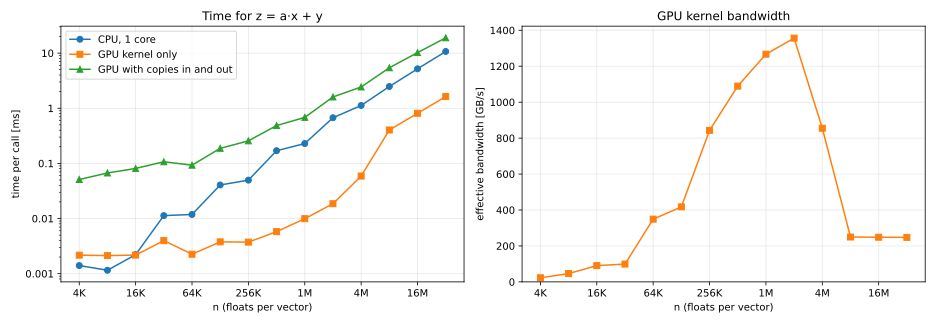

Saved /data/home/jupyter-ahiguera-mx/phlex-work/phlex-gpu-examples/build-benchmark/saxpy_benchmark.svg


In [70]:
%config InlineBackend.figure_formats = ['svg']
import csv

import numpy as np

with open(BENCH_BUILD / "saxpy_benchmark.csv") as f:
    rows = sorted(csv.DictReader(f), key=lambda r: int(r["n"]))
n = np.array([int(r["n"]) for r in rows])
col = {k: np.array([float(r[k]) for r in rows]) for k in ["h2d_ms", "kernel_ms", "d2h_ms", "cpu_ms", "kernel_gbps"]}
gpu_total = col["h2d_ms"] + col["kernel_ms"] + col["d2h_ms"]

print(f"{'n':>10} {'kernel ms':>10} {'GB/s':>8} {'GPU+copies ms':>14} {'CPU ms':>9} {'kernel speedup':>15} {'end-to-end':>11}")
for i in range(len(n)):
    print(f"{n[i]:>10} {col['kernel_ms'][i]:>10.4f} {col['kernel_gbps'][i]:>8.1f} {gpu_total[i]:>14.3f} "
          f"{col['cpu_ms'][i]:>9.3f} {col['cpu_ms'][i] / col['kernel_ms'][i]:>14.1f}x {col['cpu_ms'][i] / gpu_total[i]:>10.2f}x")

try:
    import matplotlib.pyplot as plt
except ImportError:
    print("matplotlib is not available in this kernel; the table above is the result.")
else:
    from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter

    # Plain-text tick labels: sizes as 4K ... 16M, times as 0.001 ... 100 ms
    def size_label(v, _pos=None):
        for unit, scale in (("M", 2**20), ("K", 2**10)):
            if v >= scale:
                return f"{v / scale:g}{unit}"
        return f"{v:g}"

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax in axes:
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_locator(FixedLocator(n[::2]))
        ax.xaxis.set_major_formatter(FuncFormatter(size_label))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_xlabel("n (floats per vector)")
        ax.grid(True, which="major", alpha=0.3)

    axes[0].plot(n, col["cpu_ms"], "o-", label="CPU, 1 core")
    axes[0].plot(n, col["kernel_ms"], "s-", label="GPU kernel only")
    axes[0].plot(n, gpu_total, "^-", label="GPU with copies in and out")
    axes[0].set_yscale("log")
    axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _pos: f"{v:g}"))
    axes[0].yaxis.set_minor_formatter(NullFormatter())
    axes[0].set_ylabel("time per call [ms]")
    axes[0].set_title("Time for z = a·x + y")
    axes[0].legend()

    axes[1].plot(n, col["kernel_gbps"], "s-", color="C1")
    axes[1].set_ylabel("effective bandwidth [GB/s]")
    axes[1].set_title("GPU kernel bandwidth")
    axes[1].set_ylim(bottom=0)

    fig.tight_layout()

    # Show the figure as SVG. SVG draws text from the font's outlines, while the default PNG output
    # rasterizes every glyph with FreeType, which fails in some images ("raster overflow").
    import io

    from IPython.display import SVG, display

    svg = io.StringIO()
    fig.savefig(svg, format="svg")
    plt.close(fig)
    display(SVG(svg.getvalue()))
    (BENCH_BUILD / "saxpy_benchmark.svg").write_text(svg.getvalue())
    print(f"Saved {BENCH_BUILD / 'saxpy_benchmark.svg'}")

## Reading the plots

- **Small `n`**: the kernel time hardly changes with `n`. You are measuring the cost of a launch,
  a few microseconds, not the work. The bandwidth is low because there is too little work to keep the GPU busy.
- **Middle `n`**: the bandwidth can shoot up, far above what the GPU's memory can deliver. The 50
  timed launches reuse the same three vectors, and while all three fit in the GPU's **L2 cache** (48 MB
  on an NVIDIA L4, so up to about n = 2M here), the data never leaves the chip. You are measuring the
  cache, not the memory. A real workload that streams new data each time would not see this bump.
- **Large `n`**: the vectors no longer fit in the cache, the kernel time grows in proportion to `n`,
  and the bandwidth settles on a plateau close to the GPU's memory bandwidth (about 300 GB/s on an L4).
  SAXPY does one multiply and one add per 12 bytes moved, so it is **memory-bound**: its speed is set by
  memory bandwidth, and the GPU's advantage over one CPU core is roughly the ratio of the two bandwidths,
  a few times on an L4, more on GPUs with faster memory.
- **With copies**: the copies go over PCIe, which is far slower than the GPU's own memory. For SAXPY the
  "GPU with copies" curve is usually **slower than the CPU**: you spend more time moving the data than the
  GPU saves. The `end-to-end` column in the table shows it.

The lesson for real work: **a GPU pays off when the data stays on it for a lot of work.** Copy the
inputs once, do as much as possible on the device, and copy back only the results.

> 🔬 **In an analysis:** that is why optical photon simulation works so well on GPUs. The photons
> are created, propagated and stopped on the GPU, millions of them per event, and only the few that hit
> a photon detector come back to the host. A GPU transform that copied every photon back and forth
> would lose most of the gain.



## Troubleshooting

| What you see | What it means | What to do |
|---|---|---|
| `nvidia-smi` missing, or `No devices were found` | The kernel's container was started without `--nv` | Choose the **(GPU)** kernel, or run `python3 make_gpu_kernel.py` in a terminal outside the container (Section 0), reload the page and choose the new kernel |
| `which nvcc` prints nothing, even with the GPU kernel, or CMake says `Failed to find nvcc` | The image has no CUDA toolkit; `--nv` only brings the driver | Ask your hub admin to add CUDA to the image, or to mount the host's CUDA toolkit into the kernel at `/usr/local/cuda*` (the setup cell finds it there). CUDA 13 or later works with the image's GCC 15 and needs a 580-series or newer driver; with CUDA 12 the setup cell makes nvcc use the system g++ |
| cmake stops because no GPU was detected for `CMAKE_CUDA_ARCHITECTURES` `native` | You ran cmake without a visible GPU | Rerun the setup cell (it then picks a list of architectures), or fix the GPU visibility first |
| `unsupported GNU version! gcc versions later than ... are not supported` | Your C++ compiler is newer than this CUDA release supports | Point nvcc at an older g++ with `-DCMAKE_CUDA_HOST_COMPILER=/path/to/g++-14`, or, at your own risk, `-DCMAKE_CUDA_FLAGS=-allow-unsupported-compiler`. Put it in `CUDA_CMAKE_ARGS` in the setup cell, delete the build directory and configure again |
| `CUDA driver version is insufficient for CUDA runtime version` | No driver is visible, or the driver is older than the toolkit | Check `nvidia-smi` in this notebook. If it works, the toolkit is newer than the driver: use a matching toolkit |
| `no kernel image is available for execution on the device` | The code was compiled for another GPU architecture | Configure again with a visible GPU (`native`), or add your GPU's architecture to `CMAKE_CUDA_ARCHITECTURES` |
| `Could not locate library with specification '...'` | phlex cannot find a plugin | Run the setup cell again: it puts the build directory on `PHLEX_PLUGIN_PATH` |
| `No stage name was specified` | Current phlex needs a stage | Keep `--stage gpu` on the `phlex` command line |

## Summary

| Idea | Where you used it |
|---|---|
| Warm up, time with events, average, check errors, verify | `benchmark_saxpy` in `my_saxpy_bench.cu` |
| Kernel time vs transfer time vs CPU time | the `saxpy_timing` product, the table and the left plot |
| Effective bandwidth | `kernel_gbps`, the right plot |
| A parameter scan with a layer | one spill per size, from `problem_size_source` |
| A custom struct as a data product | `saxpy_timing`, made by the transform and read by the observer |
| `concurrency::serial` for a shared resource | the GPU (transform) and the CSV file (observer) |

The minimal benchmark pattern works for any kernel: keep the steps, swap the kernel, and change the
rate you report (GB/s for memory-bound work, FLOP/s for compute-bound work).